In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('/content/datar2.csv')
display(df.head())
display(df.info())

,age,bmi,glucose,insulin,homa,leptin,adiponectin,resistin,mcp_1,classification
0,48,23.500000,70,2.707,0.467409,8.8071,9.702400,7.99585,417.114,1
1,83,20.690495,92,3.115,0.706897,8.8438,5.429285,4.06405,468.786,1
2,82,23.124670,91,4.498,1.009651,17.9393,22.432040,9.27715,554.697,1
3,68,21.367521,77,3.226,0.612725,9.8827,7.169560,12.76600,928.220,1
4,86,21.111111,92,3.549,0.805386,6.6994,4.819240,10.57635,773.920,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 116 entries, 0 to 115
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             116 non-null    int64  
 1   bmi             116 non-null    float64
 2   glucose         116 non-null    int64  
 3   insulin         116 non-null    float64
 4   homa            116 non-null    float64
 5   leptin          116 non-null    float64
 6   adiponectin     116 non-null    float64
 7   resistin        116 non-null    float64
 8   mcp_1           116 non-null    float64
 9   classification  116 non-null    int64  
dtypes: float64(7), int64(3)
memory usage: 9.2 KB


None

Now, we will prepare the features and perform K-Means clustering with $k=3$ on the dataset, assuming we want to cluster the feature space.

In [10]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Separate features (excluding classification target if present, often the last column in datar2)
# 'Classification' is typically the target column in Breast Cancer Coimbra Dataset (datar2.csv)
features = df.columns[:-1] if 'Classification' in df.columns else df.columns
X = df[features]
y = df['Classification'] if 'Classification' in df.columns else None

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Perform K-Means with k=3
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

# Display cluster distribution
print(df['Cluster'].value_counts())
display(df.groupby('Cluster').mean())

Cluster
2    55
0    51
1    10
Name: count, dtype: int64


,age,bmi,glucose,insulin,homa,leptin,adiponectin,resistin,mcp_1,classification
Cluster,,,,,,,,,,
0,55.607843,23.074883,91.078431,6.172235,1.413808,13.032435,12.807809,11.222799,430.948216,1.568627
1,60.400000,29.367173,147.100000,32.612700,11.759136,42.533810,10.476495,20.183053,816.267400,2.000000
2,58.309091,31.436984,95.054545,9.463473,2.234964,36.315582,7.691239,16.982159,579.600345,1.454545


### Cluster Visualization and Analysis
We will perform Dimensionality Reduction using PCA to plot the 3 clusters in 2D space, and analyze how clinical features differ across these clusters.

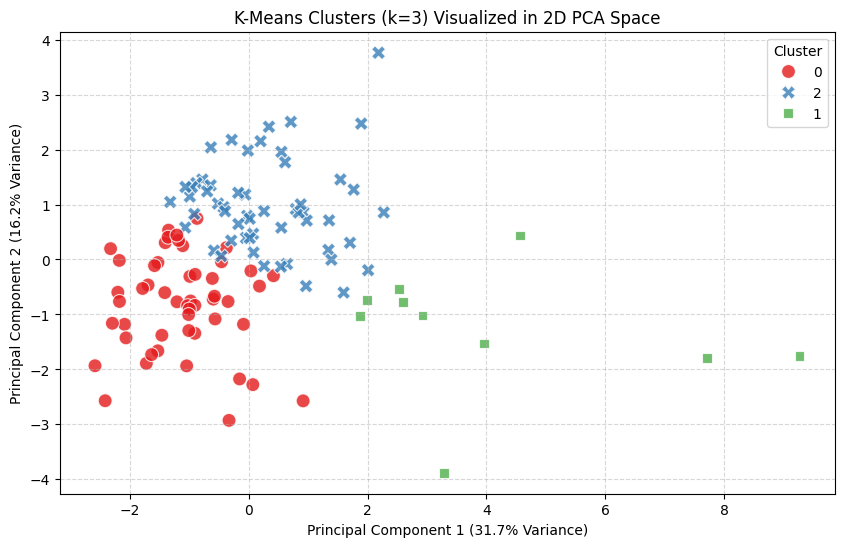

In [11]:
from sklearn.decomposition import PCA

# 1. Dimensionality Reduction using PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Store in DataFrame for plotting
df_pca = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2'])
df_pca['Cluster'] = df['Cluster'].astype(str)

# Plot PCA projection
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_pca, x='PC1', y='PC2', hue='Cluster', palette='Set1', s=100, alpha=0.8, style='Cluster')
plt.title('K-Means Clusters (k=3) Visualized in 2D PCA Space')
plt.xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)')
plt.ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

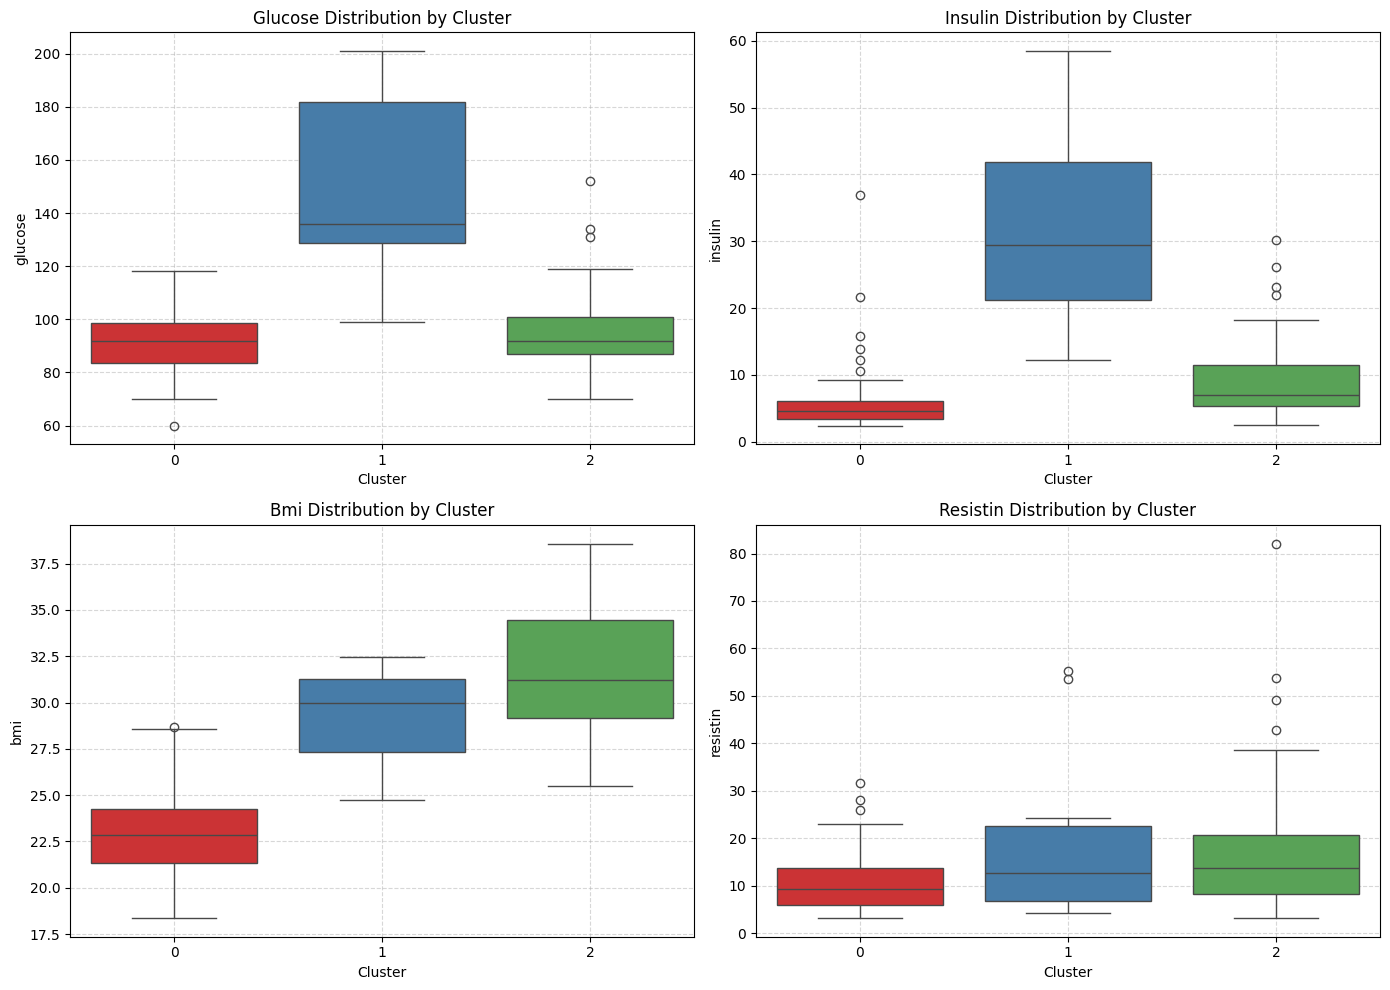

In [12]:
# 2. Analyze feature distributions across clusters
features_to_plot = ['glucose', 'insulin', 'bmi', 'resistin']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(features_to_plot):
    sns.boxplot(ax=axes[i], data=df, x='Cluster', y=col, palette='Set1', hue='Cluster', legend=False)
    axes[i].set_title(f'{col.capitalize()} Distribution by Cluster')
    axes[i].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Pairwise Feature Visualization (Without PCA)
We will generate a pair plot of key clinical features colored by their K-Means cluster assignment ($k=3$).

<Figure size 1200x1000 with 0 Axes>

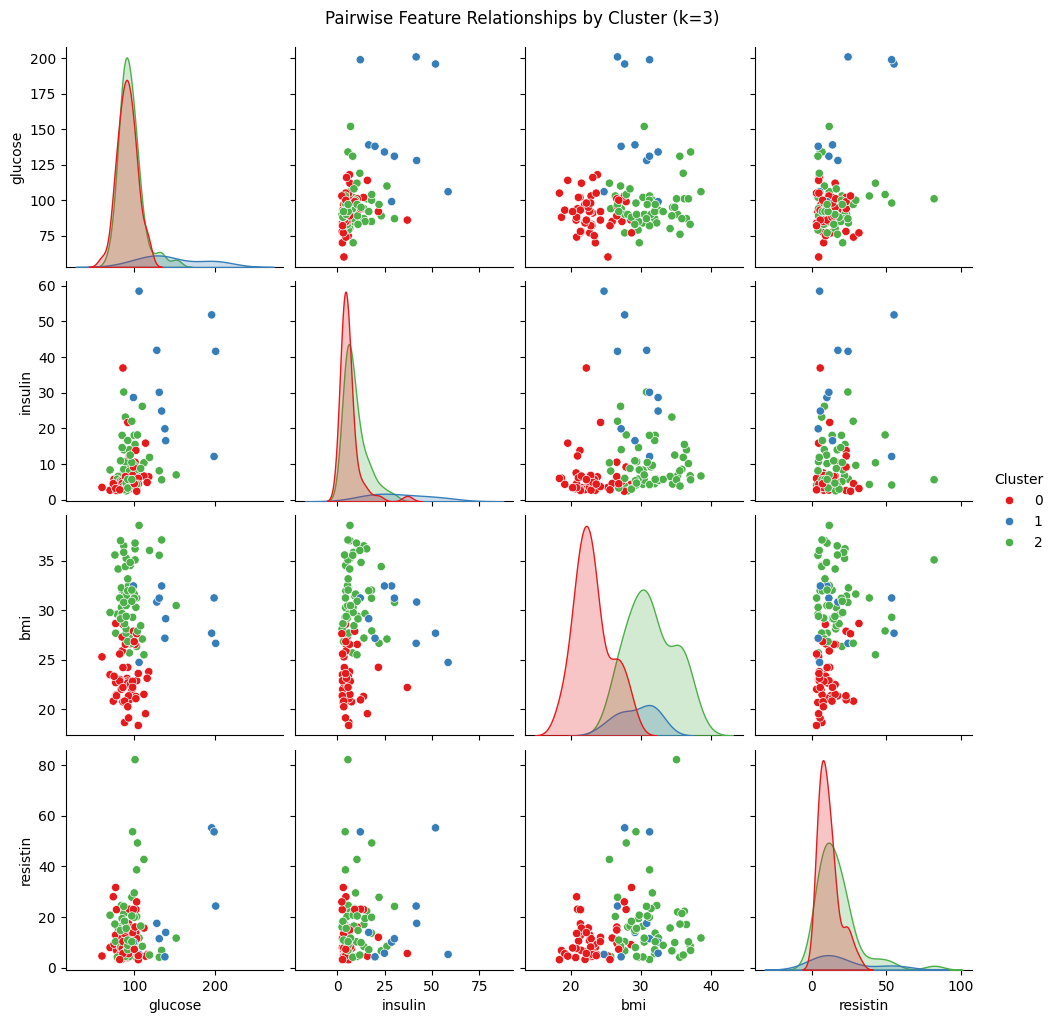

In [13]:
# Pairwise plot of key indicators colored by Cluster labels
selected_features = ['glucose', 'insulin', 'bmi', 'resistin', 'Cluster']

plt.figure(figsize=(12, 10))
sns.pairplot(df[selected_features], hue='Cluster', palette='Set1', diag_kind='kde')
plt.suptitle('Pairwise Feature Relationships by Cluster (k=3)', y=1.02)
plt.show()

### Comparing Clustering Configurations ($k = 2, 3, 4, 5$)
We will run the K-Means algorithm for multiple cluster counts ($k=2, 3, 4, 5$) and visualize the assignments in the original feature space.

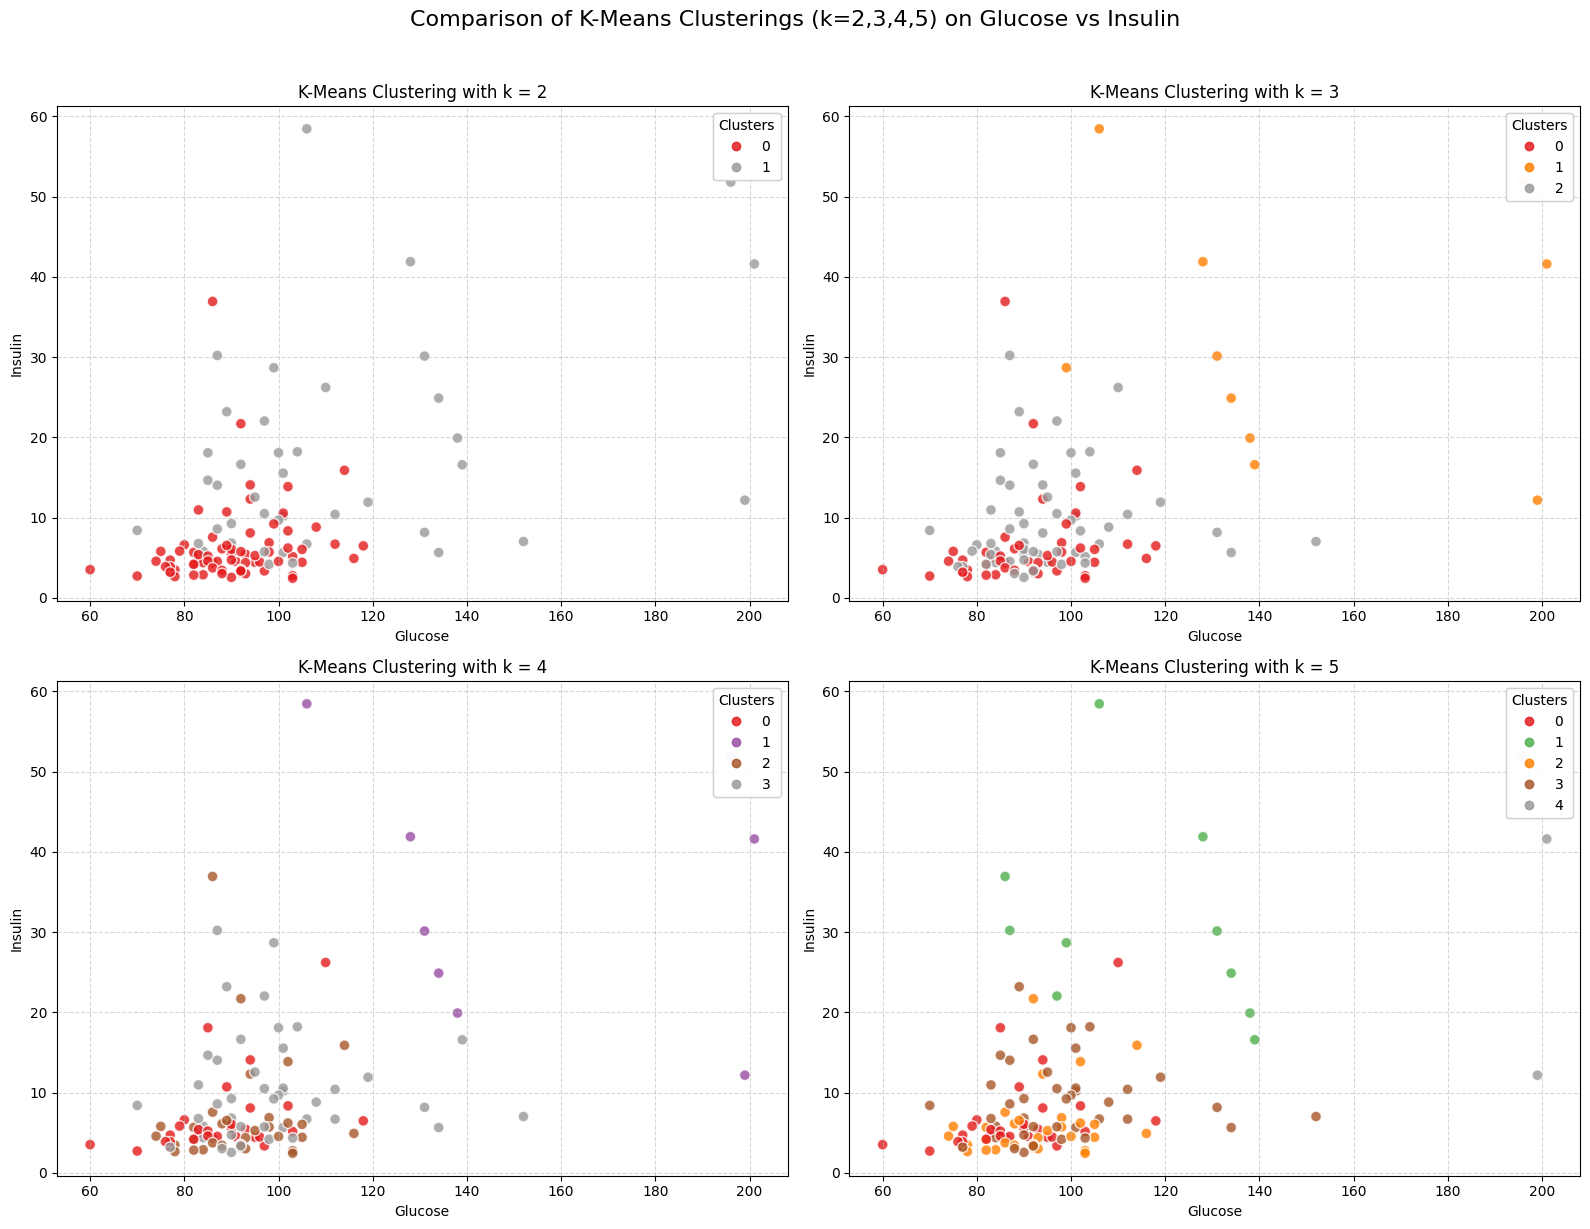

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

# We will test these k values
k_values = [2, 3, 4, 5]

for i, k in enumerate(k_values):
    # Fit K-Means
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)

    # Plot Glucose vs Insulin colored by the clusters of current k
    scatter = axes[i].scatter(df['glucose'], df['insulin'], c=labels, cmap='Set1', s=60, alpha=0.8, edgecolors='w')
    axes[i].set_title(f'K-Means Clustering with k = {k}')
    axes[i].set_xlabel('Glucose')
    axes[i].set_ylabel('Insulin')
    axes[i].grid(True, linestyle='--', alpha=0.5)

    # Add a legend for the clusters
    legend1 = axes[i].legend(*scatter.legend_elements(), title="Clusters", loc="upper right")
    axes[i].add_artist(legend1)

plt.suptitle('Comparison of K-Means Clusterings (k=2,3,4,5) on Glucose vs Insulin', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

### Classification of Clustered Data
We will use the 3-cluster labels created by K-Means as our target variable. We'll train a Random Forest Classifier and a K-Nearest Neighbors (KNN) Classifier, evaluate them, and plot their confusion matrices.

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# Prepare features (using standardized features X_scaled) and target (Cluster labels)
y_cluster = df['Cluster'].values

# Split into training and testing sets (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_cluster, test_size=0.3, random_state=42, stratify=y_cluster
)

# 1. Initialize and Train Random Forest Classifier
rf_model = RandomForestClassifier(random_state=42, n_estimators=100)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

# 2. Initialize and Train KNN Classifier
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)
y_pred_knn = knn_model.predict(X_test)

# Print classification reports
print("=== Random Forest Classification Report ===")
print(classification_report(y_test, y_pred_rf))

print("=== KNN Classification Report ===")
print(classification_report(y_test, y_pred_knn))

=== Random Forest Classification Report ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        15
           1       0.67      0.67      0.67         3
           2       0.94      0.94      0.94        17

    accuracy                           0.94        35
   macro avg       0.87      0.87      0.87        35
weighted avg       0.94      0.94      0.94        35

=== KNN Classification Report ===
              precision    recall  f1-score   support

           0       0.88      1.00      0.94        15
           1       1.00      0.67      0.80         3
           2       0.94      0.88      0.91        17

    accuracy                           0.91        35
   macro avg       0.94      0.85      0.88        35
weighted avg       0.92      0.91      0.91        35



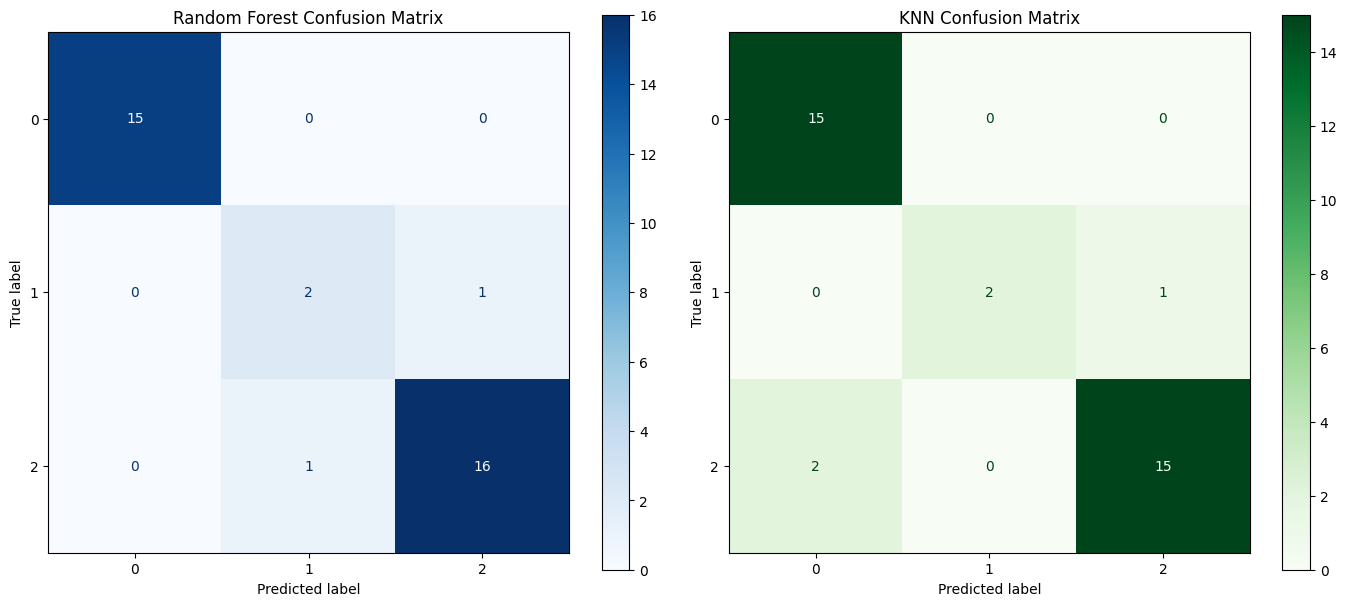

In [18]:
# Visualize Confusion Matrices side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Random Forest Confusion Matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=[0, 1, 2])
disp_rf.plot(ax=axes[0], cmap='Blues', values_format='d')
axes[0].set_title('Random Forest Confusion Matrix')

# KNN Confusion Matrix
cm_knn = confusion_matrix(y_test, y_pred_knn)
disp_knn = ConfusionMatrixDisplay(confusion_matrix=cm_knn, display_labels=[0, 1, 2])
disp_knn.plot(ax=axes[1], cmap='Greens', values_format='d')
axes[1].set_title('KNN Confusion Matrix')

plt.tight_layout()
plt.show()